In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/__results__.html
/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/submission.csv
/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/__notebook__.ipynb
/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/__output__.json
/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/roberta_sped_14m.pt
/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/custom.css
/kaggle/input/notebooks/ayanansari111/roberta-finetuned-14m/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
import pandas as pd
sample = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

In [3]:
import wandb
from kaggle_secrets import UserSecretsClient

# Fetch the secret API key from Kaggle
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

# Authenticate with Weights & Biases
wandb.login(key=wandb_api_key)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

# EDA

### Checking for NULL Values in the frame

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


### Checking for duplicated values in the frame

In [5]:
train.duplicated().sum()

np.int64(0)

In [6]:
train_copy = train.copy()
answer = train_copy['answer']
opts = []
for idx,ans in enumerate(answer):
    opts.append(train_copy.loc[idx,ans])
opts = pd.Series(opts)
train_copy['correct_option'] = opts

### Checking if there are near repeated questions

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

texts = train_copy["prompt"].tolist()
vectr = TfidfVectorizer(stop_words='english')
vec = vectr.fit_transform(texts)
sim = cosine_similarity(vec)

threshold = 1

pairs = []

for i in range(len(train_copy)):
    for j in range(i+1,(len(train_copy))):
        if sim[i,j]>=threshold:
            pairs.append((i,j,sim[i,j]))
pairs_df = pd.DataFrame(pairs, columns=["row_i", "row_j", "similarity"])
pairs_df

,row_i,row_j,similarity
0,0,1823,1.0
1,3,921,1.0
2,4,499,1.0
3,5,258,1.0
4,8,112,1.0
...,...,...,...
257,1694,1948,1.0
258,1697,1746,1.0
259,1739,1869,1.0
260,1804,1818,1.0


## Label Distribution

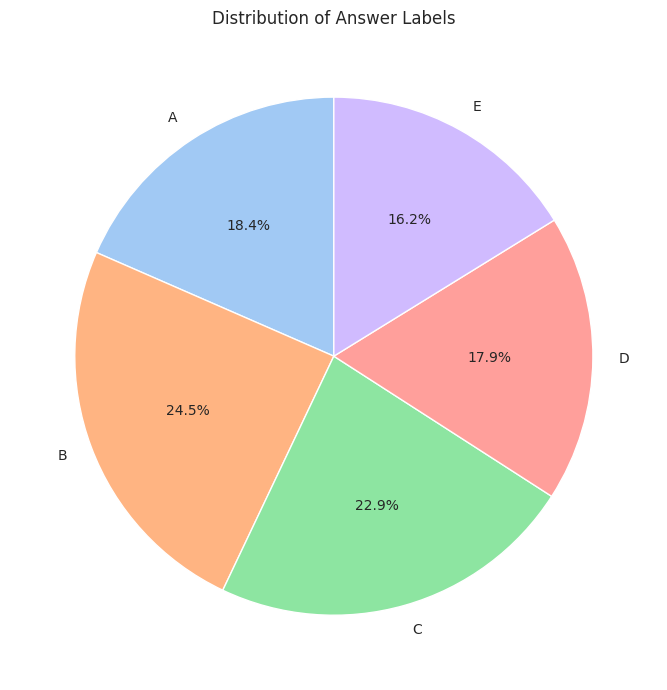

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

answer_counts = train["answer"].value_counts().sort_index()
sns.set_style("whitegrid")
colors = sns.color_palette("pastel", len(answer_counts))

plt.figure(figsize=(7, 7))
plt.pie(
    answer_counts,
    labels=answer_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
)

plt.title("Distribution of Answer Labels")
plt.tight_layout()
plt.show()

# Model Building
# 1) Finetuning a Pretrained Transformer (DeBERTa)

In [9]:
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForMultipleChoice, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
import time

## Config

In [10]:
MODEL_NAME  = "microsoft/deberta-v3-small"
MAX_LEN     = 256
BATCH_SIZE  = 16      
EPOCHS      = 5
LR          = 2e-5
LABEL_MAP   = {'A':0,'B':1,'C':2,'D':3,'E':4}
INV_LABEL_MAP = {0 :'A',1:'B',2:'C',3:'D',4:'E'}
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Dataset

In [12]:
class MCQDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        prompt  = row['prompt']
        options = [row['A'], row['B'], row['C'], row['D'], row['E']]
        label   = LABEL_MAP[row['answer']]
        
        encodings = [
            self.tokenizer(prompt, opt, truncation=True,
                           max_length=self.max_len, padding="max_length",
                           return_tensors="pt")
            for opt in options
        ]
        input_ids      = torch.stack([e["input_ids"].squeeze()      for e in encodings])  
        attention_mask = torch.stack([e["attention_mask"].squeeze() for e in encodings])
        
        return {
            "input_ids":      input_ids,
            "attention_mask": attention_mask,
            "labels":         torch.tensor(label, dtype=torch.long)
        }


In [13]:
import torch.nn as nn
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model     = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME,torch_dtype=torch.float32).to(DEVICE)

total_layers = model.config.num_hidden_layers
N_trainable = 3
for param in model.deberta.parameters():
    param.requires_grad = False

layers_to_unfreeze = range(total_layers - N_trainable, total_layers)

for i in layers_to_unfreeze:
    for param in model.deberta.encoder.layer[i].parameters():
        param.requires_grad = True

model = nn.DataParallel(model)

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin:   0%|          | 0.00/286M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

DebertaV2ForMultipleChoice LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight             

model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]

In [20]:
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6}M")

21.854977M


In [21]:
tr_df, val_df = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["answer"]
)

train_dataset = MCQDataset(tr_df, tokenizer, MAX_LEN)
val_dataset = MCQDataset(tr_df, tokenizer, MAX_LEN)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)

dataset   = MCQDataset(train, tokenizer, MAX_LEN)
loader    = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=len(loader),          
    num_training_steps=len(loader) * EPOCHS
)

## Training

In [22]:
torch.cuda.device_count()

2

In [29]:
import torch

def run_epoch(model, loader, optimizer, scheduler, device, train=True):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0

    with torch.set_grad_enabled(train):
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            if train:
                optimizer.zero_grad()

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss.mean()

            if train:
                loss.backward()
                optimizer.step()
                scheduler.step()

            total_loss += loss.item()

            preds = outputs.logits.argmax(dim=-1)
            correct += (preds == labels).sum().item()

    avg_loss = total_loss / len(loader)
    accuracy = correct / len(loader.dataset)

    return avg_loss, accuracy

In [33]:
run = wandb.init(
    name="DeBERTa 21.8M",
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="ayan-ansari7437-indian-institute-of-technology-madras",
    # Set the wandb project where this run will be logged.
    project="23f3001359-t22026",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 2e-5,
        "architecture": "DeBERTa",
        "dataset": "Training",
        "epochs": 5,
    },
)

start_time = time.time()
for epoch in range(EPOCHS):

    train_loss, train_acc = run_epoch(model=model, loader=train_loader, optimizer=optimizer,
        scheduler=scheduler, device=DEVICE, train=True)

    val_loss, val_acc = run_epoch(model=model, loader=val_loader, optimizer=None,
        scheduler=None, device=DEVICE, train=False )
    
    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )
    run.log({"Val_Accuracy": val_acc, "Val_Loss": val_loss, "Train_Accuracy":train_acc, "Train_Loss": train_loss})
end_time = time.time()

run.finish()

Epoch 1/5 | Train Loss: 0.8951 | Train Acc: 0.6525 | Val Loss: 0.4853 | Val Acc: 0.8888
Epoch 2/5 | Train Loss: 0.6693 | Train Acc: 0.7294 | Val Loss: 0.3627 | Val Acc: 0.9275
Epoch 3/5 | Train Loss: 0.5695 | Train Acc: 0.7700 | Val Loss: 0.3299 | Val Acc: 0.9387
Epoch 4/5 | Train Loss: 0.5366 | Train Acc: 0.7825 | Val Loss: 0.3058 | Val Acc: 0.9419
Epoch 5/5 | Train Loss: 0.5300 | Train Acc: 0.7950 | Val Loss: 0.3058 | Val Acc: 0.9419


Train_Accuracy,▁▅▇▇█
Train_Loss,█▄▂▁▁
Val_Accuracy,▁▆███
Val_Loss,█▃▂▁▁
Train_Accuracy,0.795
Train_Loss,0.52999
Val_Accuracy,0.94188
Val_Loss,0.30581


In [34]:
deberta_train_time = end_time - start_time
print(f"Time taken to train: {deberta_train_time}s")

Time taken to train: 687.1801092624664s


In [ ]:
# # from torch.cuda.amp import autocast, GradScaler
# # scaler = GradScaler()

# import wandb
# for epoch in range(EPOCHS):
#     model.train()
#     total_loss, correct = 0, 0

#     for batch in loader:
#         optimizer.zero_grad()
#         input_ids      = batch["input_ids"].to(DEVICE)       
#         attention_mask = batch["attention_mask"].to(DEVICE)
#         labels         = batch["labels"].to(DEVICE)          

#         outputs = model(input_ids=input_ids,
#                         attention_mask=attention_mask,
#                         labels=labels)   

#         loss = outputs.loss              
#         loss.backward()                 
#         optimizer.step()              
#         scheduler.step()
        

#         total_loss += loss.item()
#         preds = outputs.logits.argmax(dim=-1)
#         correct += (preds == labels).sum().item()

#     acc = correct / len(train)
#     print(f"Epoch {epoch+1} | Loss: {total_loss/len(loader):.4f} | Top-1 Acc: {acc:.4f}")

## Testing with one training sample

In [35]:
model.to('cuda')
model.eval()
with torch.no_grad():
    sample   = dataset[923]
    ids      = sample["input_ids"].unsqueeze(0).to(DEVICE)
    attn     = sample["attention_mask"].unsqueeze(0).to(DEVICE)
    logits   = model(input_ids=ids, attention_mask=attn).logits
    probs    = F.softmax(logits, dim=-1)
    top3_p, top3_i = torch.topk(probs, k=3, dim=-1)
    options  = ['A','B','C','D','E']
    print("Top-3 guesses:", [options[i] for i in top3_i[0].tolist()])
    print("Confidences:  ", top3_p[0].tolist())
    print(f"Actual Answer: {INV_LABEL_MAP[sample['labels'].item()]}")

Top-3 guesses: ['B', 'D', 'E']
Confidences:   [0.2979602515697479, 0.1942974478006363, 0.18321408331394196]
Actual Answer: B


## Appying on the test dataset

In [36]:
MAX_LEN  = 256       
BATCH_SZ = 16
TOP_N    = 3
LABEL_MAP_INV = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}

class MCQTestDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        prompt  = row['prompt']
        options = [row['A'], row['B'], row['C'], row['D'], row['E']]

        encodings = [
            self.tokenizer(prompt, opt,
                           truncation=True,
                           max_length=self.max_len,
                           padding="max_length",
                           return_tensors="pt")
            for opt in options
        ]

        input_ids      = torch.stack([e["input_ids"].squeeze()      for e in encodings])
        attention_mask = torch.stack([e["attention_mask"].squeeze() for e in encodings]) 

        return {
            "input_ids":      input_ids,
            "attention_mask": attention_mask,
            "id":             row["id"],
        }

test_dataset = MCQTestDataset(test, tokenizer, MAX_LEN)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SZ, shuffle=False)

In [37]:
model.eval()

all_ids         = []
all_top_n_labels = []
all_top_n_probs  = []

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch["input_ids"].to(DEVICE)      
        attention_mask = batch["attention_mask"].to(DEVICE) 
        ids            = batch["id"].tolist()               

        outputs = model(input_ids=input_ids,
                        attention_mask=attention_mask)      
        probs   = F.softmax(outputs.logits, dim=-1)        

        top_probs, top_idx = torch.topk(probs, k=3, dim=-1)  

        for i, qid in enumerate(ids):
            labels_i = [LABEL_MAP_INV[j.item()] for j in top_idx[i]]
            probs_i  = [round(p.item(), 4) for p in top_probs[i]]

            all_ids.append(qid)
            all_top_n_labels.append(labels_i)
            all_top_n_probs.append(probs_i)

In [38]:
submission = pd.DataFrame({
    "ID":        all_ids,
    "Prediction": [" ".join(labels) for labels in all_top_n_labels],  
})
submission.to_csv("submission.csv", index=False)
print(submission.head())

   ID Prediction
0   1      A C D
1   2      B C A
2   3      B E D
3   4      E C D
4   5      C A D


In [ ]:
# sample1 = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
# sample1

In [40]:
import os
# save_dir = "/kaggle/working/mcq_deberta_model"
# os.makedirs(save_dir, exist_ok=True)

save_dir = "/kaggle/working/deberta_finetuned"

# Move underlying model to CPU (optional)
model.module.to("cpu")

# Save the underlying Hugging Face model
model.module.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/deberta_finetuned/tokenizer_config.json',
 '/kaggle/working/deberta_finetuned/tokenizer.json')

# 2) Custom built Transformer Encoder

In [3]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer
import time

## Config

In [4]:
TOKENIZER_NAME = "bert-base-uncased"
MAX_LEN    = 256 #128
D_MODEL    = 512 #256
N_HEADS    = 16 #8
N_LAYERS   = 8 #4
FFN_DIM    = 512
DROPOUT    = 0.1
BATCH_SIZE = 16
EPOCHS     = 5
LR         = 3e-4
TOP_N      = 1
CHOICES    = ["A", "B", "C", "D", "E"]
LABEL_MAP  = {c: i for i, c in enumerate(CHOICES)}
INV_LABEL  = {i: c for c, i in LABEL_MAP.items()}
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## Dataset

In [5]:
class MCQDataset(Dataset):
    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt = str(row["prompt"])

        all_ids, all_masks = [], []
        for choice in CHOICES:
            enc = tokenizer(
                prompt,
                str(row[choice]),
                truncation=True,
                padding="max_length",
                max_length=MAX_LEN,
                return_tensors="pt"
            )
            all_ids.append(enc["input_ids"].squeeze())
            all_masks.append(enc["attention_mask"].squeeze())

        item = {
            "input_ids": torch.stack(all_ids),       
            "attention_mask": torch.stack(all_masks), 
        }

        if self.has_labels:
            item["label"] = torch.tensor(LABEL_MAP[row["answer"]])

        return item

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [9]:
class TransformerMCQ(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(
            tokenizer.vocab_size, D_MODEL,
            padding_idx=tokenizer.pad_token_id
        )
        self.pos_enc = PositionalEncoding(D_MODEL)
        self.dropout = nn.Dropout(DROPOUT)

        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL, nhead=N_HEADS,
            dim_feedforward=FFN_DIM, dropout=DROPOUT,
            activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=N_LAYERS)
        self.fc = nn.Linear(D_MODEL, 1)

    def encode(self, input_ids, attention_mask):
        pad_mask = (attention_mask == 0)
        x = self.dropout(self.pos_enc(self.embedding(input_ids)))
        x = self.encoder(x, src_key_padding_mask=pad_mask)
        return self.dropout(x[:, 0, :])

    def forward(self, input_ids, attention_mask):
        B, N, L = input_ids.shape
        ids   = input_ids.view(B * N, L)
        masks = attention_mask.view(B * N, L)
        out   = self.fc(self.encode(ids, masks))
        return out.view(B, N)

In [11]:
def get_accuracy(logits, labels, k=1):
    top_preds = torch.topk(logits,k=k).indices
    labels = labels.view(-1,1)
    correct = (top_preds == labels).any(dim=1)
    accuracy = correct.float().mean()
    return accuracy.item()

# def map3(logits, labels):
#     top_preds = torch.topk(logits,k=TOP_N).indices
#     indices = top_preds.squeeze(0).tolist()  

def run_epoch(model, loader, criterion, optimizer=None):
    if optimizer:
        istrain = True
    else:
        istrain = False
    
    model.train() if istrain else model.eval()

    total_loss, n = 0, 0
    all_logits, all_labels = [], []

    if istrain:
        ctx = torch.enable_grad()
    else:
        ctx = torch.no_grad()
    
    with ctx:
        for batch in loader:
            ids    = batch["input_ids"].to(DEVICE)
            masks  = batch["attention_mask"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits = model(ids, masks)
            loss   = criterion(logits, labels)

            if istrain:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            n += labels.size(0)
            all_logits.append(logits.detach().cpu())
            all_labels.append(labels.cpu())

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)

    return total_loss / n, get_accuracy(logits, labels, TOP_N)

In [12]:
tr_df, val_df = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["answer"]
)

train_dataset = MCQDataset(tr_df)
val_dataset = MCQDataset(val_df)
test_dataset = MCQDataset(test, has_labels = False)

train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE)

model     = TransformerMCQ()
model     = nn.DataParallel(model)
model     = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print(f"Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

/tmp/ipykernel_58/762310506.py:16: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=N_LAYERS)


Params: 28,251,649


## Setting up WandB

In [13]:
import wandb
from kaggle_secrets import UserSecretsClient

# Fetch the secret API key from Kaggle
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

# Authenticate with Weights & Biases
wandb.login(key=wandb_api_key)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [14]:
import wandb

run = wandb.init(
    name="Transformer Encoder 512-dim",
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="ayan-ansari7437-indian-institute-of-technology-madras",
    # Set the wandb project where this run will be logged.
    project="23f3001359-t22026",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 3e-4,
        "architecture": "Transformer Encoder",
        "dataset": "Training",
        "epochs": 5,
    },
)

start_time = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_accN = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_accN = run_epoch(model, val_loader,   criterion)
    scheduler.step()

    print(f"Epoch {epoch:02d} | Training: Loss = {tr_loss:.4f} Accuracy = {tr_accN:.4f}"
          f" | Validation: Loss = {va_loss:.4f} Accuracy = {va_accN:.4f}")

    # if epoch%2 == 0:
    run.log({"Val_Accuracy": va_accN, "Val_Loss": va_loss, "Train_Accuracy":tr_accN, "Train_Loss": tr_loss})

end_time = time.time()
run.finish()

Epoch 01 | Training: Loss = 1.3071 Accuracy = 0.4856 | Validation: Loss = 0.5341 Accuracy = 0.7725
Epoch 02 | Training: Loss = 0.6197 Accuracy = 0.7725 | Validation: Loss = 0.2214 Accuracy = 0.9525
Epoch 03 | Training: Loss = 0.3281 Accuracy = 0.8838 | Validation: Loss = 0.0421 Accuracy = 0.9875
Epoch 04 | Training: Loss = 0.1458 Accuracy = 0.9506 | Validation: Loss = 0.0262 Accuracy = 0.9875
Epoch 05 | Training: Loss = 0.1381 Accuracy = 0.9506 | Validation: Loss = 0.0255 Accuracy = 0.9900


Train_Accuracy,▁▅▇██
Train_Loss,█▄▂▁▁
Val_Accuracy,▁▇███
Val_Loss,█▄▁▁▁
Train_Accuracy,0.95063
Train_Loss,0.13812
Val_Accuracy,0.99
Val_Loss,0.02551


In [15]:
print(f"Time taken to train: {end_time-start_time}s")

Time taken to train: 275.5999312400818s


## Testing on one training sample

In [16]:
model.eval()
with torch.no_grad():
    sample_test = train_dataset[1320]
    sample_test_inputids = sample_test["input_ids"].unsqueeze(0).to(DEVICE)
    sample_test_attention = sample_test["attention_mask"].unsqueeze(0).to(DEVICE)
    logits = model(sample_test_inputids,sample_test_attention)
    prob = F.softmax(logits,dim=-1)
    confs, top_indices = torch.topk(prob,k=3)
    top_indices = top_indices.squeeze(0).tolist()
    top_guess = [INV_LABEL[index] for index in top_indices]
    print(f"Top 3 guesses : {top_guess}")
    print(f"Actual answer: {INV_LABEL[sample_test["label"].item()]}")
    print(f"Confidences: {confs}")

Top 3 guesses : ['B', 'C', 'A']
Actual answer: B
Confidences: tensor([[1.0000e+00, 2.0226e-08, 1.3457e-08]], device='cuda:0')


## Inferencing on the test dataset

In [20]:
def predict(model, loader):
    model.eval()
    all_labels, all_probs = [], []

    with torch.no_grad():
        for batch in loader:
            ids   = batch["input_ids"].to(DEVICE)
            masks = batch["attention_mask"].to(DEVICE)
            logits = model(ids, masks)
            probs = F.softmax(logits, dim=-1)
            top_p, top_i = torch.topk(probs, 3, dim=-1)

            for i in range(ids.size(0)):
                all_labels.append([INV_LABEL[j.item()] for j in top_i[i]])
                all_probs.append([round(p.item(), 4) for p in top_p[i]])

    return all_labels, all_probs

In [21]:
labels, probs = predict(model,test_loader)
prediction = [" ".join(label) for label in labels]
ids = [i for i in range(1,len(prediction)+1)]
submission = pd.DataFrame({"ID":ids,"Prediction":prediction})
submission.to_csv('submission.csv',index=False)

In [22]:
submission.head()

,ID,Prediction
0,1,A E D
1,2,B C E
2,3,B D E
3,4,E C D
4,5,C A D


## Saving the transformer encoder model

In [23]:
import os
save_dir = "/kaggle/working/transformer_model"
os.makedirs(save_dir, exist_ok=True)

# model.to("cpu")
# model.save_pretrained(save_dir)
# tokenizer.save_pretrained(save_dir)

# print("Saved model to:", save_dir)

model_save_path = "/kaggle/working/transformer_model/mcq_transformer_model.pth"
torch.save(model.state_dict(), model_save_path)
print(f"Model saved to {model_save_path}")

Model saved to /kaggle/working/transformer_model/mcq_transformer_model.pth


# 3)RoBERTa Finetuned

In [37]:
from transformers import AutoModelForMultipleChoice, AutoTokenizer
from torch.utils.data import Dataset, DataLoader
import torch
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
import torch
import torch.nn as nn

MAX_LEN     = 256
BATCH_SIZE  = 16
EPOCHS      = 5
LR          = 2e-4
LABEL_MAP   = {'A':0,'B':1,'C':2,'D':3,'E':4}
INV_LABEL_MAP = {0 :'A',1:'B',2:'C',3:'D',4:'E'}
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
options = ['A','B','C','D','E']

In [38]:
model = AutoModelForMultipleChoice.from_pretrained("roberta-base")
tokenizer = AutoTokenizer.from_pretrained('roberta-base')
print(sum(p.numel() for p in model.parameters() if p.requires_grad))
num_encoder_layers = len(model.roberta.encoder.layer)
print(f"Number of encoder layers: {num_encoder_layers}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForMultipleChoice LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.pooler.dense.weight     | MISSING    | 
classifier.weight               | MISSING    | 
roberta.pooler.dense.bias       | MISSING    | 
classifier.bias                 | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


124646401
Number of encoder layers: 12


In [39]:
# Freeze all parameters first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the last 4 encoder layers
num_layers = len(model.roberta.encoder.layer)
for i in range(num_layers - 2, num_layers):
    for param in model.roberta.encoder.layer[i].parameters():
        param.requires_grad = True

# Also unfreeze the pooler and classifier
if hasattr(model.roberta, 'pooler'):
    for param in model.roberta.pooler.parameters():
        param.requires_grad = True

if hasattr(model, 'classifier'):
    for param in model.classifier.parameters():
        param.requires_grad = True

print(f"Number of trainable parameters after freezing: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6}M")

Number of trainable parameters after freezing: 14.767105M


In [42]:
class MCQDataset(Dataset):
    def __init__(self, df, has_labels=False):
        self.df = df
        self.tokenizer = tokenizer
        self.max_length = MAX_LEN
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        prompt = row['prompt']
        input_ids = []
        attention_mask = []

        for opt in options:
            opt_text = row[opt]
            encoding = self.tokenizer(prompt, opt_text, max_length=self.max_length,
                                  truncation = True, padding='max_length', return_tensors='pt')
            input_ids.append(encoding['input_ids'])
            attention_mask.append(encoding['attention_mask'])

        input_ids = torch.stack(input_ids)
        attention_mask = torch.stack(attention_mask)

        if self.has_labels:
            labels = torch.tensor(LABEL_MAP[row['answer']])
            return {
                'input_ids': input_ids,
                'attention_mask': attention_mask,
                'labels': labels
            }
        return {
            'input_ids': input_ids,
            'attention_mask': attention_mask,
            'id': row['id']
        } 

In [43]:
tr_df, val_df = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["answer"]
)
train_dataset = MCQDataset(tr_df, has_labels=True)
val_dataset = MCQDataset(val_df, has_labels=True)
test_dataset = MCQDataset(test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, shuffle=False)

In [44]:
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=len(train_loader),
    num_training_steps=len(train_loader) * EPOCHS
)

In [49]:
def run_epoch(model, loader, optimizer, scheduler, device, train=True):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0

    with torch.set_grad_enabled(train):
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            if train:
                optimizer.zero_grad()

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss.mean()

            if train:
                loss.backward()
                optimizer.step()
                scheduler.step()

            total_loss += loss.item()

            preds = outputs.logits.argmax(dim=-1)
            correct += (preds == labels).sum().item()

    avg_loss = total_loss / len(loader)
    accuracy = correct / len(loader.dataset)

    return avg_loss, accuracy

In [50]:
import wandb
import time

run = wandb.init(
    name="RoBERTa 14.7M",
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="ayan-ansari7437-indian-institute-of-technology-madras",
    # Set the wandb project where this run will be logged.
    project="23f3001359-t22026",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 2e-4,
        "architecture": "RoBERTa",
        "dataset": "Training",
        "epochs": 5,
    },
)

model = nn.DataParallel(model)
model.to(DEVICE)
for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss, train_acc = run_epoch(model=model, loader=train_loader, optimizer=optimizer,
        scheduler=scheduler, device=DEVICE, train=True)

    train_end_time = time.time()
    train_time = train_end_time - start_time

    val_loss, val_acc = run_epoch(model=model, loader=val_loader, optimizer=None,
        scheduler=None, device=DEVICE, train=False )

    val_end_time = time.time()
    val_time = val_end_time - train_end_time

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Train Time: {train_time:.2f}s | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
        f"Val Time: {val_time:.2f}s"
    )

    run.log({"Val_Accuracy": val_acc, "Val_Loss": val_loss, "Train_Accuracy":train_acc, "Train_Loss": train_loss})

end_time = time.time()
run.finish()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch 1/5 | Train Loss: 1.5370 | Train Acc: 0.2888 | Train Time: 95.91s | Val Loss: 0.8819 | Val Acc: 0.6425 | Val Time: 15.95s
Epoch 2/5 | Train Loss: 0.6298 | Train Acc: 0.7656 | Train Time: 93.16s | Val Loss: 0.2243 | Val Acc: 0.9400 | Val Time: 15.44s
Epoch 3/5 | Train Loss: 0.2630 | Train Acc: 0.8994 | Train Time: 93.31s | Val Loss: 0.1027 | Val Acc: 0.9850 | Val Time: 15.54s
Epoch 4/5 | Train Loss: 0.1424 | Train Acc: 0.9425 | Train Time: 93.82s | Val Loss: 0.0419 | Val Acc: 0.9850 | Val Time: 15.83s
Epoch 5/5 | Train Loss: 0.0989 | Train Acc: 0.9606 | Train Time: 93.41s | Val Loss: 0.0397 | Val Acc: 0.9875 | Val Time: 15.49s


Train_Accuracy,▁▆▇██
Train_Loss,█▄▂▁▁
Val_Accuracy,▁▇███
Val_Loss,█▃▂▁▁
Train_Accuracy,0.96062
Train_Loss,0.09891
Val_Accuracy,0.9875
Val_Loss,0.03975


In [58]:
print(f"Total time taken to Train: {(end_time-start_time)*5}s")

Total time taken to Train: 544.4752931594849s


In [53]:
import torch.nn.functional as F
model.to('cuda')
model.eval()
with torch.no_grad():
    sample   = train_dataset[923]
    ids      = sample["input_ids"].unsqueeze(0).to(DEVICE)
    attn     = sample["attention_mask"].unsqueeze(0).to(DEVICE)
    logits   = model(input_ids=ids, attention_mask=attn).logits
    probs    = F.softmax(logits, dim=-1)
    top3_p, top3_i = torch.topk(probs, k=3, dim=-1)
    options  = ['A','B','C','D','E']
    print("Top-3 guesses:", [options[i] for i in top3_i[0].tolist()])
    print("Confidences:  ", top3_p[0].tolist())
    print(f"Actual Answer: {INV_LABEL_MAP[sample['labels'].item()]}")

Top-3 guesses: ['C', 'B', 'A']
Confidences:   [0.9999998807907104, 6.183979195384381e-08, 4.5169151974278066e-08]
Actual Answer: C


In [54]:
model.eval()

all_ids         = []
all_top_n_labels = []
all_top_n_probs  = []

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        ids            = batch["id"].tolist()

        outputs = model(input_ids=input_ids,
                        attention_mask=attention_mask)
        probs   = F.softmax(outputs.logits, dim=-1)

        top_probs, top_idx = torch.topk(probs, k=3, dim=-1)

        for i, qid in enumerate(ids):
            labels_i = [INV_LABEL_MAP[j.item()] for j in top_idx[i]]
            probs_i  = [round(p.item(), 4) for p in top_probs[i]]

            all_ids.append(qid)
            all_top_n_labels.append(labels_i)
            all_top_n_probs.append(probs_i)

In [55]:
submission = pd.DataFrame({
    "ID":        all_ids,
    "Prediction": [" ".join(labels) for labels in all_top_n_labels],
})
submission.to_csv("submission.csv", index=False)
print(submission.head())

   ID Prediction
0   1      A E C
1   2      B E A
2   3      B E D
3   4      E C D
4   5      C A B


In [56]:
# 1. Save the model's state dictionary
torch.save(model.state_dict(), 'roberta_sped_14m.pt')
print("Model state dictionary saved as 'roberta_sped_14m.pt'")

Model state dictionary saved as 'roberta_sped_14m.pt'
